In [1]:
import pandas as pd

In [2]:
from langchain_community.chat_models import ChatLlamaCpp

model_path = "./Llama-3.2-3B-Instruct-Q4_K_M.gguf"

llm = ChatLlamaCpp(
    model_path=model_path,
    temperature=0.7,
    n_ctx=2048,
    n_gpu_layers=-1,
    verbose=False
)

response = llm.invoke("Hello! What is LangChain? Answer in one sentence.")
print(response.content)

/var/folders/1n/l6k6vm8d181fnbjj5lp3xhqm0000gn/T/ipykernel_44411/3992296927.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.chat_models import ChatLlamaCpp


LangChain is an open-source, decentralized framework for building web applications that interact with blockchain networks.


In [3]:
books = pd.read_csv("dataset.csv", low_memory=False)

In [4]:

books.head()

,book_id,title,subtitle,series_name,series_position,authors,description,genres,language,format,...,reviews_count,price_usd,isbn,thumbnail_url,source_url,sample_review,source_dataset,source_record_id,date_ingested,approx_sales_millions
0,bk_feb496fb94195ca3,Officer Off Limits,NaN,Line of Duty,3,Tessa Bailey,His need to possess her is non-negotiable. Sto...,Romance|Contemporary Romance|Contemporary|Erot...,en,NaN,...,30.0,NaN,9781622662197,https://m.media-amazon.com/images/S/compressed...,https://www.amazon.com/gp/product/B00CQYAW3I/r...,5 “You’ve got sixty seconds to prove you’re no...,goodreads_books_dataset,17910375,2026-11-08,NaN
1,bk_559dc92e931c5530,Loathe to Love You,NaN,The STEMinist Novellas,1-3,Ali Hazelwood,"Мара, Сейді та Ханна ще з коледжу звикли підтр...",Romance|Contemporary|Contemporary Romance|Fict...,en,NaN,...,30.0,NaN,9781408726778,https://m.media-amazon.com/images/S/compressed...,https://www.amazon.com/gp/product/B0B64YB46G/r...,“ali hazelwood writes the same books but in di...,goodreads_books_dataset,59054191,2026-11-08,NaN
2,bk_22cdbfceb2fe5497,Asking for Trouble,NaN,Line of Duty,4,Tessa Bailey,A sexy category romance from Entangled's Braze...,Romance|Contemporary Romance|Contemporary|Enem...,en,NaN,...,30.0,NaN,9781622663521,https://m.media-amazon.com/images/S/compressed...,https://www.amazon.com/gp/product/B00FIL334Q/r...,4 There is a thin line between love and hate S...,goodreads_books_dataset,18593366,2026-11-08,NaN
3,bk_4c7f14df324a587d,คินดะอิจิยอดนักสืบ ตอนที่ 32 กระดิ่งลมหัวคน,NaN,Detective Kosuke Kindaichi,32,Seishi Yokomizo,คดีสุดท้ายของนักสืบชื่อดังคินดะอิจิ โคสุเกะ ก่...,Mystery|Novels,th,NaN,...,5.0,NaN,9786167757384,https://m.media-amazon.com/images/S/compressed...,http://www.amazon.com/gp/product/6167757380/re...,The House of Hanging On the Hospital Slope vol...,goodreads_books_dataset,27559206,2026-11-08,NaN
4,bk_2526a2da723d5d0a,Three Bags Full,NaN,Sheep Detective Story,1,Leonie Swann,Soon to be a major motion picture starring Hug...,Mystery|Fiction|Crime|Animals|Humor|Fantasy|Au...,en,NaN,...,30.0,NaN,9781641296823,https://m.media-amazon.com/images/S/compressed...,https://www.amazon.com/gp/product/B0D5GWGB13/r...,This is one of the weirdest books I have ever ...,goodreads_books_dataset,213960819,2026-11-08,NaN


In [5]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 57332 entries, 0 to 57331
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   book_id                57332 non-null  str    
 1   title                  57331 non-null  str    
 2   subtitle               1760 non-null   str    
 3   series_name            408 non-null    str    
 4   series_position        393 non-null    str    
 5   authors                55428 non-null  str    
 6   description            1125 non-null   str    
 7   genres                 57097 non-null  str    
 8   language               50091 non-null  str    
 9   format                 14046 non-null  str    
 10  first_published_year   55881 non-null  float64
 11  publication_date       866 non-null    str    
 12  pages                  1060 non-null   float64
 13  rating                 1145 non-null   float64
 14  ratings_count          903 non-null    float64
 15  reviews_count

In [6]:
books.isnull().sum()

book_id                      0
title                        1
subtitle                 55572
series_name              56924
series_position          56939
authors                   1904
description              56207
genres                     235
language                  7241
format                   43286
first_published_year      1451
publication_date         56466
pages                    56272
rating                   56187
ratings_count            56429
reviews_count            56158
price_usd                57061
isbn                     56652
thumbnail_url            30889
source_url                 436
sample_review            56543
source_dataset               0
source_record_id             0
date_ingested                0
approx_sales_millions    57167
dtype: int64

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

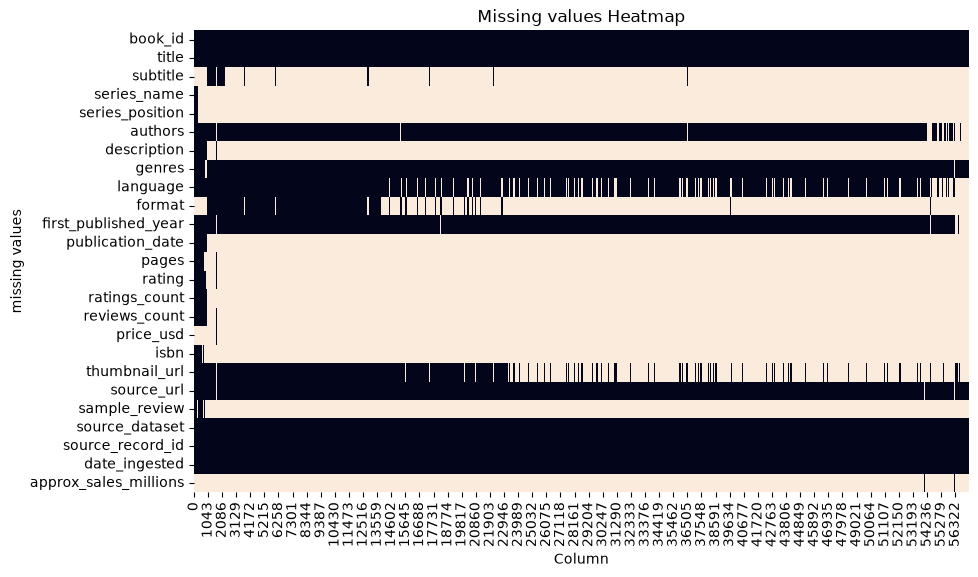

In [8]:
fig, ax = plt.subplots(figsize=(10, 6)) 

sns.heatmap(books.isna().transpose(), cbar=False, ax=ax)

plt.xlabel("Column")
plt.ylabel("missing values")
plt.title("Missing values Heatmap") 
plt.show()

In [9]:
import numpy as np

#1) column setting
books["missing_description"] = np.where(books["description"].isna(), 1, 0)

#2)Calculate the age of the book using "first_published_year"
books["age_of_book"] = 2026 - books["first_published_year"]

books[["first_published_year", "age_of_book", "missing_description"]].head()

,first_published_year,age_of_book,missing_description
0,2013.0,13.0,0
1,2023.0,3.0,0
2,2013.0,13.0,0
3,2015.0,11.0,0
4,2025.0,1.0,0


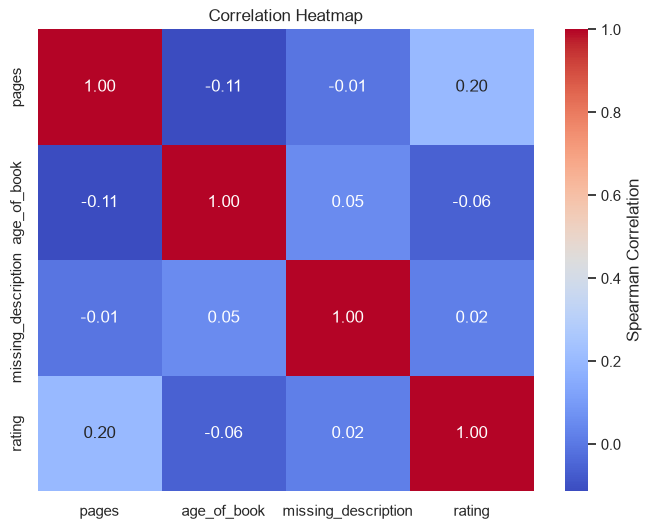

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_of_interest = ["pages", "age_of_book", "missing_description", "rating"]

#correlation matrix
correlation_matrix = books[columns_of_interest].corr(method="spearman")

sns.set_theme(style="white")
plt.figure(figsize=(8, 6))

heatmap = sns.heatmap(
    correlation_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    cbar_kws={'label': 'Spearman Correlation'}
)

heatmap.set_title("Correlation Heatmap")
plt.show()